# Target-free ASSCGD-inspired 4× MRI reconstruction

This notebook records the completed **50-epoch / 94,900-step** self-supervised
diffusion experiment. Five checkpoints were screened on validation data, and the
selected checkpoint was evaluated once on the held-out test set. The validation
screen covers epochs **10, 20, 30, 40, and 50**.

The implementation is **ASSCGD/SSAD-MRI-inspired**, rather than a claim of exact
reproduction: it keeps this project's conditional U-Net, uses supplied sensitivity
maps, and combines held-out acquired k-space supervision with adversarial diffusion
training. Fully sampled images were never used to optimize the model; they are loaded
only for validation checkpoint selection and final evaluation.

References: [paper preprint](https://arxiv.org/abs/2406.15656) ·
[official ReconFormer repository](https://github.com/guopengf/ReconFormer)

In [1]:
from pathlib import Path
from html import escape
import json, re
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
ASSCGD_ROOT = Path('/data/david_agyei/nyu-dataset/derived/asscgd_4x_stable')
EVAL = ASSCGD_ROOT / 'evaluation'

def read_json(path):
    return json.loads(Path(path).read_text())

def show_table(rows, columns, precision=4):
    def render(value):
        if isinstance(value, float):
            return f'{value:.{precision}f}'
        return escape(str(value))
    header = ''.join(f'<th style="text-align:left;padding:4px 10px">{escape(label)}</th>' for _, label in columns)
    body = ''.join('<tr>' + ''.join(
        f'<td style="text-align:left;padding:4px 10px">{render(row[key])}</td>' for key, _ in columns
    ) + '</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

selection = read_json(EVAL / 'best_validation_checkpoint.json')
selected_step = selection['checkpoint_step']
test_dir = EVAL / 'test' / f'step-{selected_step:07d}'
test = read_json(test_dir / 'summary.json')
test_slices = [json.loads(line) for line in (test_dir / 'slice_metrics.jsonl').read_text().splitlines() if line]
progression = read_json(ROOT / 'results/asscgd_evaluation/qualitative/progression_metadata.json')
print(f"Selected checkpoint: epoch {selection['completed_epochs']}, step {selected_step:,}")

Selected checkpoint: epoch 50, step 94,900


## Protocol and data integrity

Splits are frozen at the volume level, preventing slices from the same volume from
appearing in multiple splits. Training dynamically divides each acquired 4× mask into
input and held-out lines while always retaining ACS lines in the input. The loss uses
only held-out measured k-space; validation and test targets are evaluation-only.

In [2]:
integrity = [
    {'Split': 'Train', 'Volumes': 120, 'Slices': 1898, 'Role': 'target-free optimization'},
    {'Split': 'Validation', 'Volumes': 14, 'Slices': 220, 'Role': 'checkpoint selection'},
    {'Split': 'Test', 'Volumes': test['volume_count'], 'Slices': test['slice_count'], 'Role': 'final reporting'},
]
show_table(integrity, [(key, key) for key in ['Split', 'Volumes', 'Slices', 'Role']], precision=0)
protocol = [
    {'Setting': 'Acceleration', 'Value': '4× Cartesian'},
    {'Setting': 'Sensitivity maps', 'Value': 'supplied maps only'},
    {'Setting': 'Training target', 'Value': 'held-out acquired k-space'},
    {'Setting': 'Diffusion schedule', 'Value': '100 train / 10 sampling steps'},
    {'Setting': 'Inference noise seed', 'Value': test['noise_seed']},
    {'Setting': 'Runtime measurement', 'Value': 'shared GPU; descriptive only'},
]
show_table(protocol, [('Setting', 'Setting'), ('Value', 'Value')], precision=0)

Split,Volumes,Slices,Role
Train,120,1898,target-free optimization
Validation,14,220,checkpoint selection
Test,14,218,final reporting


Setting,Value
Acceleration,4× Cartesian
Sensitivity maps,supplied maps only
Training target,held-out acquired k-space
Diffusion schedule,100 train / 10 sampling steps
Inference noise seed,20261021
Runtime measurement,shared GPU; descriptive only


## Training stability

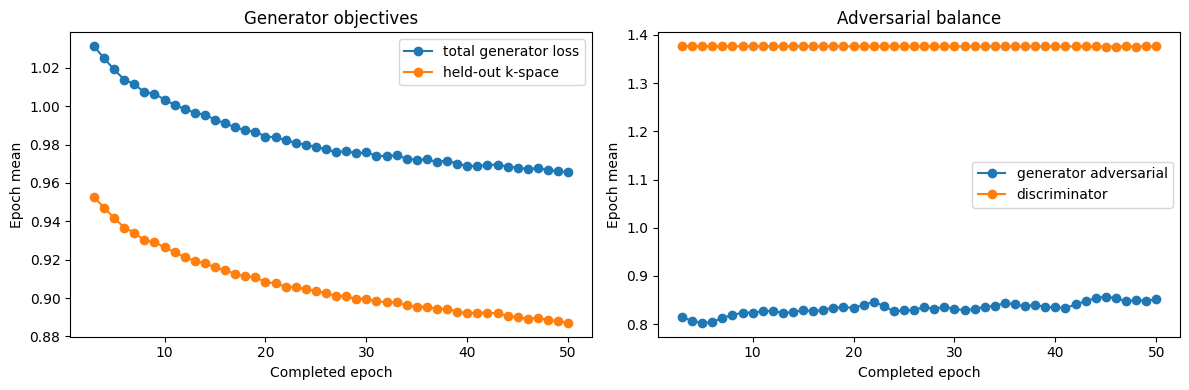

Logged stabilized run: epochs 3–50.
Final means: loss=0.9656, held-out=0.8871, generator adversarial=0.8522, discriminator=1.3760.


In [3]:
pattern = re.compile(
    r'epoch_complete=(\d+)/\d+ step=(\d+) mean_loss=([0-9.eE+-]+) '
    r'mean_heldout=([0-9.eE+-]+) mean_g_adv=([0-9.eE+-]+) mean_d=([0-9.eE+-]+)'
)
records = []
for line in (ASSCGD_ROOT / 'train.log').read_text().splitlines():
    match = pattern.search(line)
    if match:
        records.append(tuple(float(value) for value in match.groups()))
records = sorted({int(row[0]): row for row in records}.values())
epochs = np.array([int(row[0]) for row in records])
loss = np.array([row[2] for row in records])
heldout = np.array([row[3] for row in records])
g_adv = np.array([row[4] for row in records])
disc = np.array([row[5] for row in records])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, loss, marker='o', label='total generator loss')
axes[0].plot(epochs, heldout, marker='o', label='held-out k-space')
axes[0].set(xlabel='Completed epoch', ylabel='Epoch mean', title='Generator objectives')
axes[0].legend()
axes[1].plot(epochs, g_adv, marker='o', label='generator adversarial')
axes[1].plot(epochs, disc, marker='o', label='discriminator')
axes[1].set(xlabel='Completed epoch', ylabel='Epoch mean', title='Adversarial balance')
axes[1].legend()
plt.tight_layout(); plt.show()
print(f'Logged stabilized run: epochs {epochs[0]}–{epochs[-1]}.')
print(f'Final means: loss={loss[-1]:.4f}, held-out={heldout[-1]:.4f}, '
      f'generator adversarial={g_adv[-1]:.4f}, discriminator={disc[-1]:.4f}.')

The generator recovered from the epoch-2 checkpoint with the stabilized discriminator
configuration. The stable log therefore starts at epoch 3. Held-out k-space loss falls
gradually while discriminator loss remains near 1.376, avoiding the earlier collapsed
discriminator regime.

## Validation checkpoint selection

Epoch,Step,PSNR ↑,SSIM ↑,Complex NMSE ↓,Residual ↓
10,18980,32.5504,0.6909,0.0227,0.1443
20,37960,33.2892,0.6860,0.0190,0.1436
30,56940,33.9076,0.8170,0.0177,0.1444
40,75920,33.5764,0.6817,0.0176,0.1439
50,94900,34.3798,0.7794,0.0157,0.1437


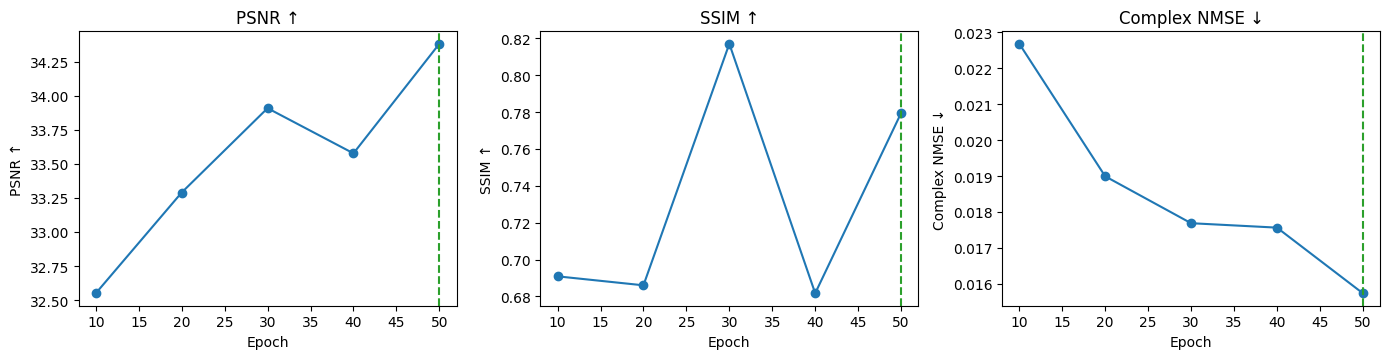

Epoch 50 was selected by maximum volume-averaged validation PSNR.


In [4]:
validation = [{
    'Epoch': row['completed_epochs'], 'Step': row['checkpoint_step'],
    'PSNR ↑': row['asscgd']['psnr'], 'SSIM ↑': row['asscgd']['ssim'],
    'Complex NMSE ↓': row['asscgd']['nmse'],
    'Residual ↓': row['asscgd']['measurement_residual'],
} for row in selection['candidates']]
show_table(validation, [(key, key) for key in validation[0]])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for axis, metric in zip(axes, ['PSNR ↑', 'SSIM ↑', 'Complex NMSE ↓']):
    axis.plot([row['Epoch'] for row in validation], [row[metric] for row in validation], marker='o')
    axis.axvline(selection['completed_epochs'], color='tab:green', linestyle='--')
    axis.set(xlabel='Epoch', ylabel=metric, title=metric)
plt.tight_layout(); plt.show()
print(f"Epoch {selection['completed_epochs']} was selected by maximum volume-averaged validation PSNR.")

## Held-out test result

In [5]:
comparison = []
for name, values in [('Zero-filled', test['zero_filled']), ('ASSCGD-inspired', test['asscgd'])]:
    comparison.append({
        'Method': name, 'Complex NMSE ↓': values['nmse'],
        'Magnitude PSNR ↑': values['psnr'], 'Magnitude SSIM ↑': values['ssim'],
        'Residual ↓': values['measurement_residual'],
        'Seconds/slice† ↓': values.get('seconds_per_slice', np.nan),
    })
show_table(comparison, [(key, key) for key in comparison[0]])

psnr_gain = test['asscgd']['psnr'] - test['zero_filled']['psnr']
ssim_change = test['asscgd']['ssim'] - test['zero_filled']['ssim']
nmse_reduction = 100 * (1 - test['asscgd']['nmse'] / test['zero_filled']['nmse'])
residual_reduction = 100 * (1 - test['asscgd']['measurement_residual'] / test['zero_filled']['measurement_residual'])
print(f'ASSCGD vs zero-filled: {psnr_gain:+.2f} dB PSNR, {ssim_change:+.4f} SSIM, '
      f'{nmse_reduction:.1f}% lower NMSE, and {residual_reduction:.1f}% lower measurement residual.')

Method,Complex NMSE ↓,Magnitude PSNR ↑,Magnitude SSIM ↑,Residual ↓,Seconds/slice† ↓
Zero-filled,0.0714,29.7164,0.8295,0.1622,nan
ASSCGD-inspired,0.0373,33.8366,0.7569,0.1508,0.2995


ASSCGD vs zero-filled: +4.12 dB PSNR, -0.0726 SSIM, 47.7% lower NMSE, and 7.0% lower measurement residual.


† The final checkpoint was evaluated while the unrolled-RDBM experiment was training
on the same GPU. Reconstruction time therefore describes this run under shared load;
it is not an isolated speed benchmark. Image-quality metrics are unaffected.

### Results by acquisition

Acquisition,Volumes,ZF PSNR,ASSCGD PSNR,ZF SSIM,ASSCGD SSIM,ZF NMSE,ASSCGD NMSE
AXFLAIR,2,28.5068,31.1304,0.7856,0.6606,0.1538,0.1334
AXT1POST,10,29.9895,34.3456,0.8333,0.7695,0.0560,0.0205
AXT1PRE,2,29.5610,33.9978,0.8545,0.7903,0.0655,0.0250


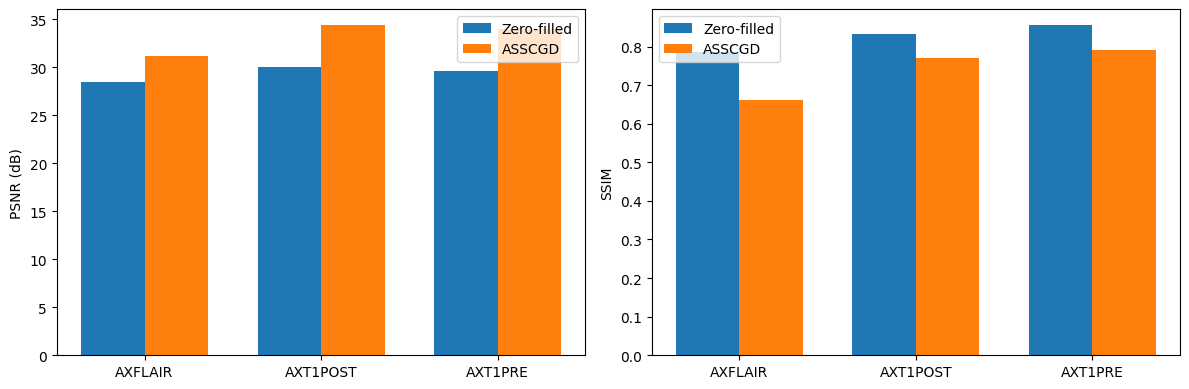

In [6]:
acquisition = []
for name, group in test['by_acquisition'].items():
    acquisition.append({
        'Acquisition': name, 'Volumes': group['volume_count'],
        'ZF PSNR': group['zero_filled']['psnr'], 'ASSCGD PSNR': group['asscgd']['psnr'],
        'ZF SSIM': group['zero_filled']['ssim'], 'ASSCGD SSIM': group['asscgd']['ssim'],
        'ZF NMSE': group['zero_filled']['nmse'], 'ASSCGD NMSE': group['asscgd']['nmse'],
    })
show_table(acquisition, [(key, key) for key in acquisition[0]])

x = np.arange(len(acquisition)); width = .36
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(x-width/2, [row['ZF PSNR'] for row in acquisition], width, label='Zero-filled')
axes[0].bar(x+width/2, [row['ASSCGD PSNR'] for row in acquisition], width, label='ASSCGD')
axes[0].set_xticks(x, [row['Acquisition'] for row in acquisition]); axes[0].set_ylabel('PSNR (dB)'); axes[0].legend()
axes[1].bar(x-width/2, [row['ZF SSIM'] for row in acquisition], width, label='Zero-filled')
axes[1].bar(x+width/2, [row['ASSCGD SSIM'] for row in acquisition], width, label='ASSCGD')
axes[1].set_xticks(x, [row['Acquisition'] for row in acquisition]); axes[1].set_ylabel('SSIM'); axes[1].legend()
plt.tight_layout(); plt.show()

## Slice- and volume-level behavior

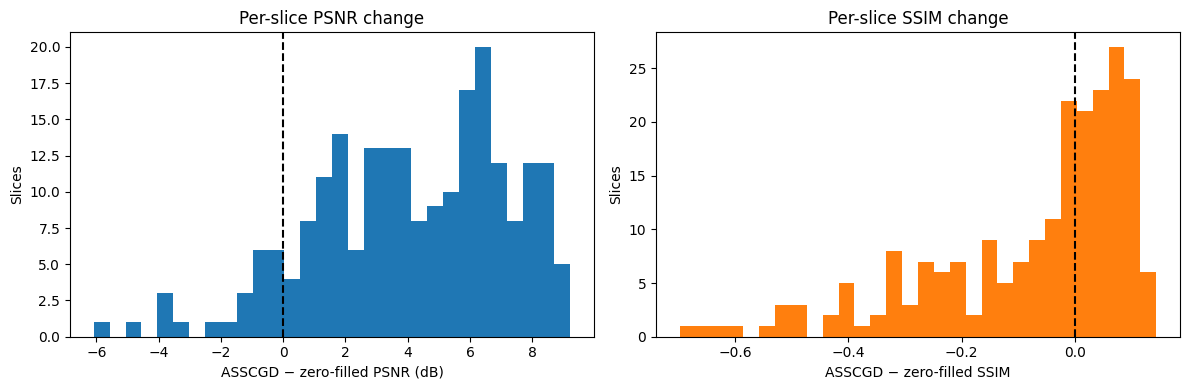

PSNR improves on 90.4% of test slices; SSIM improves on 48.6%.


Volume,Acquisition,ZF PSNR,ASSCGD PSNR,PSNR gain,ZF SSIM,ASSCGD SSIM
file_brain_AXFLAIR_202_6000575,AXFLAIR,26.0292,27.8641,1.8349,0.7075,0.5718
file_brain_AXT1POST_209_6001292,AXT1POST,31.4362,34.3128,2.8766,0.8646,0.7642
file_brain_AXT1PRE_201_6002729,AXT1PRE,28.6553,31.6872,3.0319,0.8372,0.7366
file_brain_AXT1POST_203_6000889,AXT1POST,29.6845,32.9451,3.2606,0.8334,0.7245
file_brain_AXT1POST_203_6000895,AXT1POST,28.3800,31.6918,3.3118,0.8119,0.6632
file_brain_AXFLAIR_203_6000916,AXFLAIR,30.9845,34.3968,3.4123,0.8637,0.7495
file_brain_AXT1POST_203_6000832,AXT1POST,30.3063,34.4595,4.1532,0.8342,0.7641
file_brain_AXT1POST_208_2080524,AXT1POST,30.6380,34.9680,4.3300,0.8269,0.7963
file_brain_AXT1POST_200_6002386,AXT1POST,28.6857,33.1758,4.4901,0.7950,0.7537
file_brain_AXT1POST_202_6000285,AXT1POST,31.2835,36.2297,4.9462,0.8551,0.8190


In [7]:
slice_psnr_gain = np.array([row['asscgd_psnr'] - row['zero_filled_psnr'] for row in test_slices])
slice_ssim_gain = np.array([row['asscgd_ssim'] - row['zero_filled_ssim'] for row in test_slices])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(slice_psnr_gain, bins=30, color='tab:blue'); axes[0].axvline(0, color='black', linestyle='--')
axes[0].set(xlabel='ASSCGD − zero-filled PSNR (dB)', ylabel='Slices', title='Per-slice PSNR change')
axes[1].hist(slice_ssim_gain, bins=30, color='tab:orange'); axes[1].axvline(0, color='black', linestyle='--')
axes[1].set(xlabel='ASSCGD − zero-filled SSIM', ylabel='Slices', title='Per-slice SSIM change')
plt.tight_layout(); plt.show()
print(f'PSNR improves on {100*np.mean(slice_psnr_gain > 0):.1f}% of test slices; '
      f'SSIM improves on {100*np.mean(slice_ssim_gain > 0):.1f}%.')

volumes = [{
    'Volume': item['volume_id'], 'Acquisition': item['acquisition'],
    'ZF PSNR': item['zero_filled']['psnr'], 'ASSCGD PSNR': item['asscgd']['psnr'],
    'PSNR gain': item['asscgd']['psnr'] - item['zero_filled']['psnr'],
    'ZF SSIM': item['zero_filled']['ssim'], 'ASSCGD SSIM': item['asscgd']['ssim'],
} for item in test['volumes']]
show_table(sorted(volumes, key=lambda row: row['PSNR gain']), [(key, key) for key in volumes[0]])

## Reconstruction across training checkpoints

The example is selected automatically as the test slice closest to the median ASSCGD
PSNR gain. All checkpoints use the same deterministic inference noise. The top row is
magnitude; the lower row is absolute magnitude error against the fully sampled target.

Sample: file_brain_AXFLAIR_203_6000916:7 (index 23)


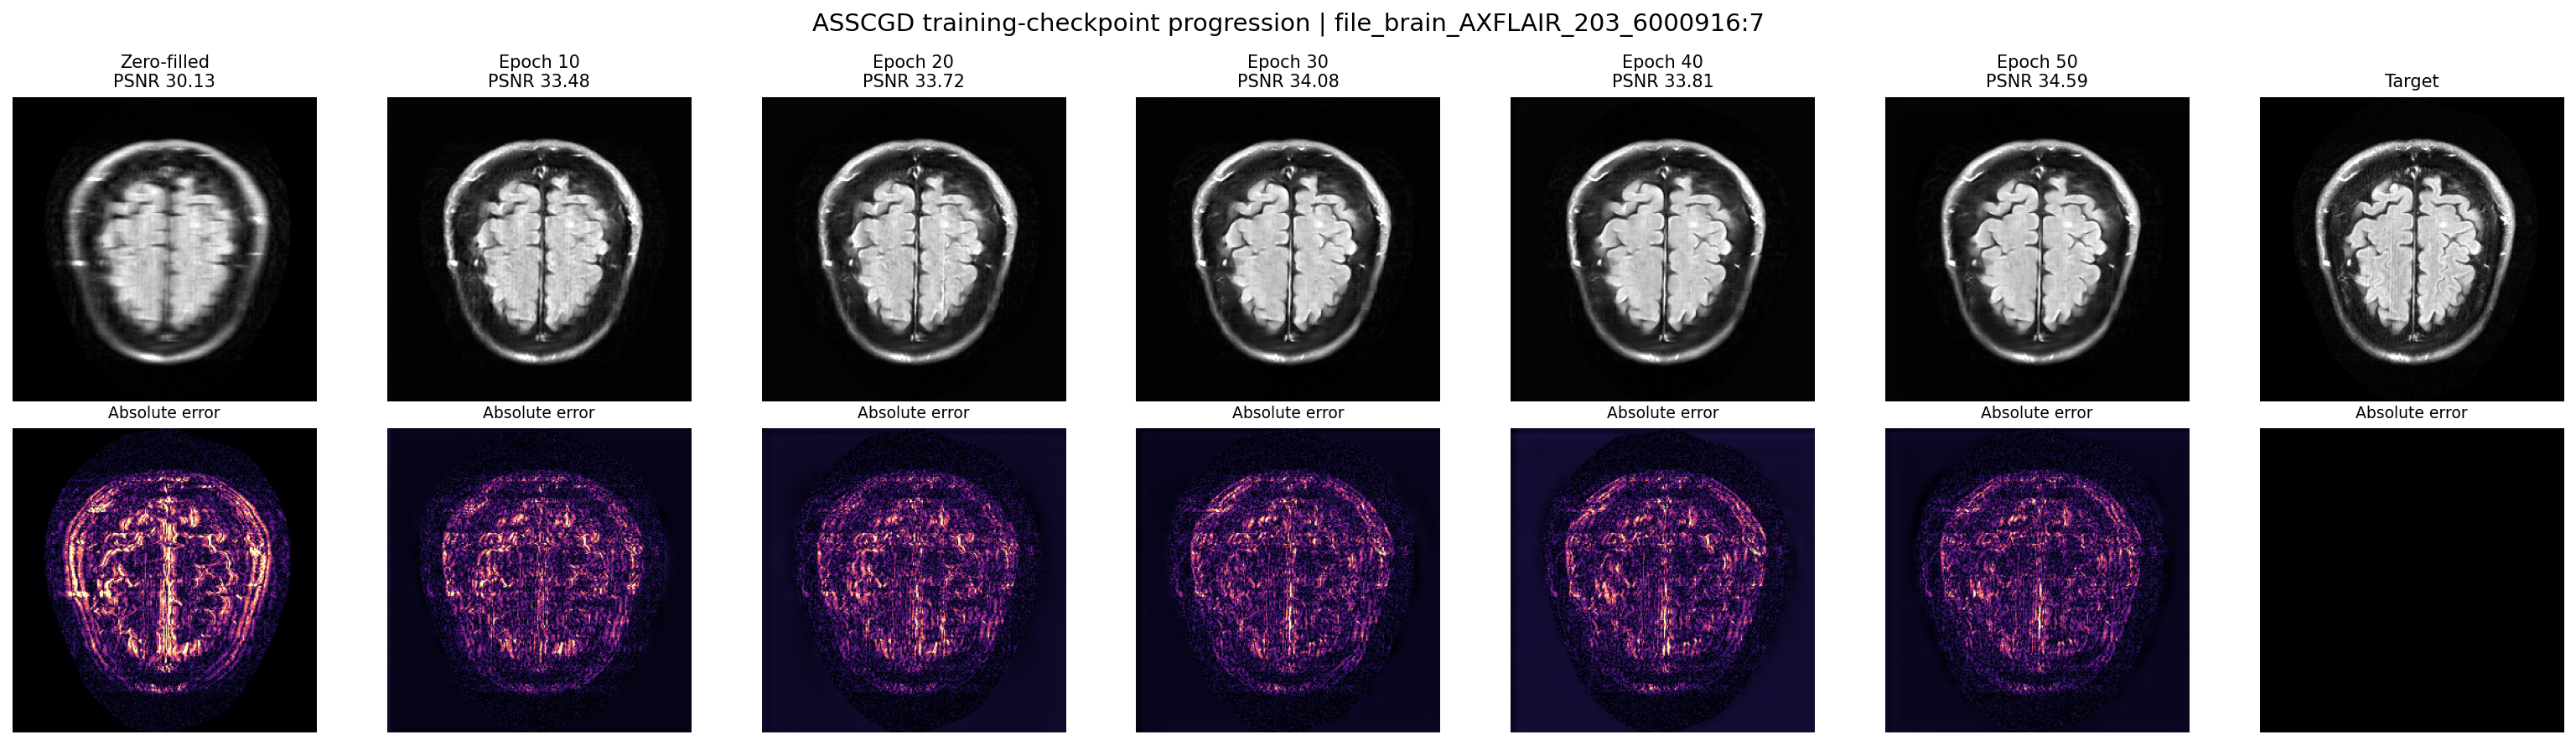

In [8]:
print(f"Sample: {progression['sample_id']} (index {progression['sample_index']})")
display(Image(filename=str(ROOT / 'results/asscgd_evaluation/qualitative/checkpoint_progression.png')))

## Reverse-diffusion reconstruction timeline

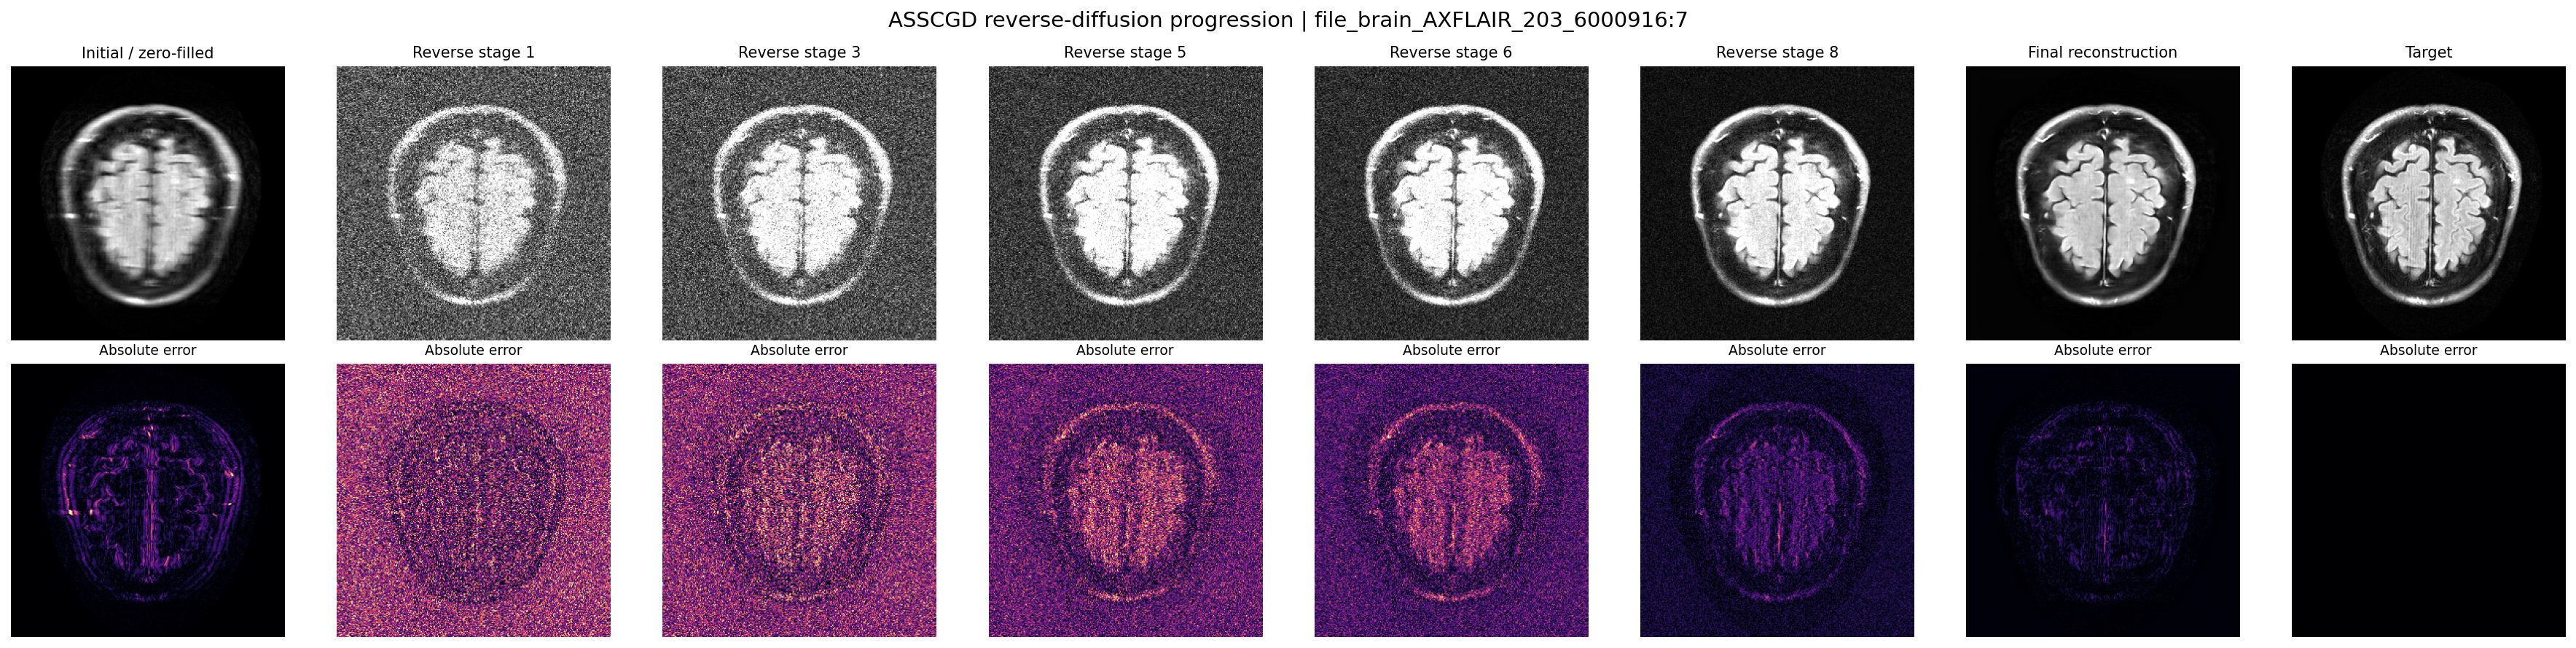

State,NMSE,PSNR,SSIM
zero_filled,0.0561,30.1307,0.8482
step_18980,0.0295,33.4846,0.8486
step_37960,0.0272,33.7208,0.7911
step_56940,0.0258,34.0829,0.8289
step_75920,0.0258,33.8090,0.7594
step_94900,0.0227,34.5922,0.8255


In [9]:
display(Image(filename=str(ROOT / 'results/asscgd_evaluation/qualitative/reverse_diffusion_progression.png')))
metric_rows = []
for name, values in progression['metrics'].items():
    metric_rows.append({'State': name, 'NMSE': values['nmse'], 'PSNR': values['psnr'], 'SSIM': values['ssim']})
show_table(metric_rows, [(key, key) for key in metric_rows[0]])

## Interpretation and limitations

- The self-supervised model improves test magnitude PSNR, complex NMSE, and acquired-line
  consistency over the zero-filled reconstruction without using fully sampled training targets.
- Magnitude SSIM decreases overall. The model sharpens the reconstruction and reduces global
  squared error, but its local structural contrast does not yet match the target reliably.
- AXFLAIR contains only two test volumes and has substantially worse complex NMSE than the T1
  acquisitions, so the aggregate should always be reported with this stratified breakdown.
- Evaluation uses one deterministic noise realization per slice. This makes checkpoint comparison
  and reruns reproducible, but it does not estimate uncertainty across stochastic samples.
- Reconstruction timing was measured under concurrent GPU load and should not be used for a
  direct speed comparison with models benchmarked on an otherwise idle GPU.
- This is an ASSCGD/SSAD-MRI-inspired adaptation using the existing conditional U-Net and supplied
  sensitivity maps. Architecture and dataset differences prevent direct numerical comparison with
  the paper's reported results.

The clearest next experiment is to improve the image-domain objective or architecture with SSIM
as a validation constraint, while retaining the target-free held-out k-space protocol.

## Reproducibility artifacts

In [10]:
artifacts = [
    {'Artifact': 'Checkpoint selection', 'Path': str(EVAL / 'best_validation_checkpoint.json')},
    {'Artifact': 'Test summary', 'Path': str(test_dir / 'summary.json')},
    {'Artifact': 'Test slice metrics', 'Path': str(test_dir / 'slice_metrics.jsonl')},
    {'Artifact': 'Training log', 'Path': str(ASSCGD_ROOT / 'train.log')},
    {'Artifact': 'Progression metadata', 'Path': str(ROOT / 'results/asscgd_evaluation/qualitative/progression_metadata.json')},
]
show_table(artifacts, [('Artifact', 'Artifact'), ('Path', 'Path')], precision=0)

Artifact,Path
Checkpoint selection,/data/david_agyei/nyu-dataset/derived/asscgd_4x_stable/evaluation/best_validation_checkpoint.json
Test summary,/data/david_agyei/nyu-dataset/derived/asscgd_4x_stable/evaluation/test/step-0094900/summary.json
Test slice metrics,/data/david_agyei/nyu-dataset/derived/asscgd_4x_stable/evaluation/test/step-0094900/slice_metrics.jsonl
Training log,/data/david_agyei/nyu-dataset/derived/asscgd_4x_stable/train.log
Progression metadata,/home/david/Project-with-Diffusion-model-using-NYU-Dataset-w-Moj-/results/asscgd_evaluation/qualitative/progression_metadata.json
